<a href="https://colab.research.google.com/github/valverdeelias951-cell/ProyectoP1/blob/main/Proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Parcial I Predicción del rendimiento académico con aprendizaje automático

**Integrantes:**
- EVELYN BRITTANI AGUIRRE ZAMBRANO
- ERICK FERNANDO FUERTES ALCIVAR
- HELEN ANAHI MISES MEZA
-  ELIAS ESTEBAN VALVERDE BENALCAZAR

**Paralelo:** CDDEIA-ELMA-4-1

**Fecha:** 29/11/2026

## Librerias

In [ ]:
# Librerías principales
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, confusion_matrix)

sns.set_style("whitegrid")

# Semilla del grupo (NO puede ser 42). Justificarla en la celda de texto de abajo.
SEMILLA = 2026

In [3]:
# lo descarga desde el repositorio de GitHub (repositorio público del grupo).
URL = "https://raw.githubusercontent.com/valverdeelias951-cell/ProyectoP1/main/student-mat.csv"

df = None
for ruta in ["student-mat.csv", "/student-mat.csv"]:
    if os.path.exists(ruta):
        df = pd.read_csv(ruta)
        break
if df is None:
    df = pd.read_csv(URL)

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Justificación de la semilla:** Elegimos la semilla 2026, que corresponde al año en que desarrollamos este proyecto. Usamos una semilla fija para que los resultados sean reproducibles: con el mismo número, la división entre entrenamiento (80 %) y prueba (20 %) y la elección al azar de los valores faltantes son siempre las mismas, y cualquier integrante del grupo o el docente puede obtener exactamente las mismas métricas al ejecutar el notebook. No elegimos el 42, como indica la consigna, y este valor tampoco fue seleccionado por ofrecer mejores resultados: no probamos varias semillas para quedarnos con la que diera mejores métricas, ya que eso sería sesgar la evaluación del modelo.

# Parte 1. Análisis exploratorio de datos (EDA)

## 1.1 Estructura del dataset

In [4]:
# Dimensiones del dataset
print("Filas y columnas:", df.shape)

# Tipos de variables y valores no nulos
df.info()

Filas y columnas: (395, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-nu

In [5]:
# Estadísticas descriptivas de las variables numéricas
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Descripción de la estructura:** El dataset tiene 395 filas (estudiantes) y 33 columnas, sin valores nulos. Hay 16 variables numéricas (como age, studytime, absences, G1, G2 y G3) y 17 categóricas (como school, sex, Mjob e internet). En las estadísticas descriptivas, las notas G1, G2 y G3 promedian alrededor de 10 a 11 puntos sobre 20. En absences el promedio es bajo, pero el máximo es muy alto, lo que sugiere valores atípicos.

Verifica en tu df.info() que los conteos (16 y 17) coincidan, y en df.describe() el promedio y el máximo de absences.

In [6]:
# Estadísticas de las variables categóricas
df.describe(include="object")

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


## 1.2 Distribución de G3 y de variables relevantes

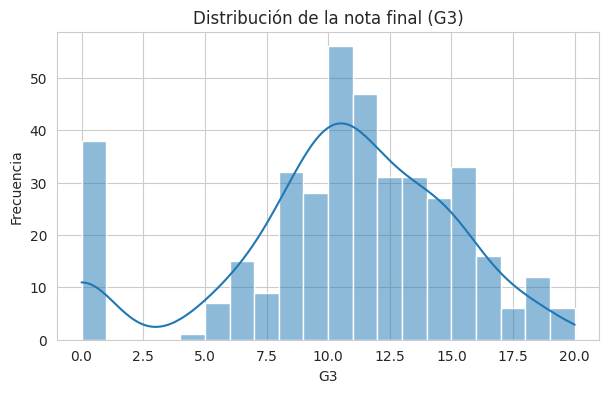

Estudiantes con G3 = 0: 38


In [7]:
# Distribución de la nota final G3
plt.figure(figsize=(7, 4))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribución de la nota final (G3)")
plt.xlabel("G3")
plt.ylabel("Frecuencia")
plt.show()

print("Estudiantes con G3 = 0:", (df["G3"] == 0).sum())

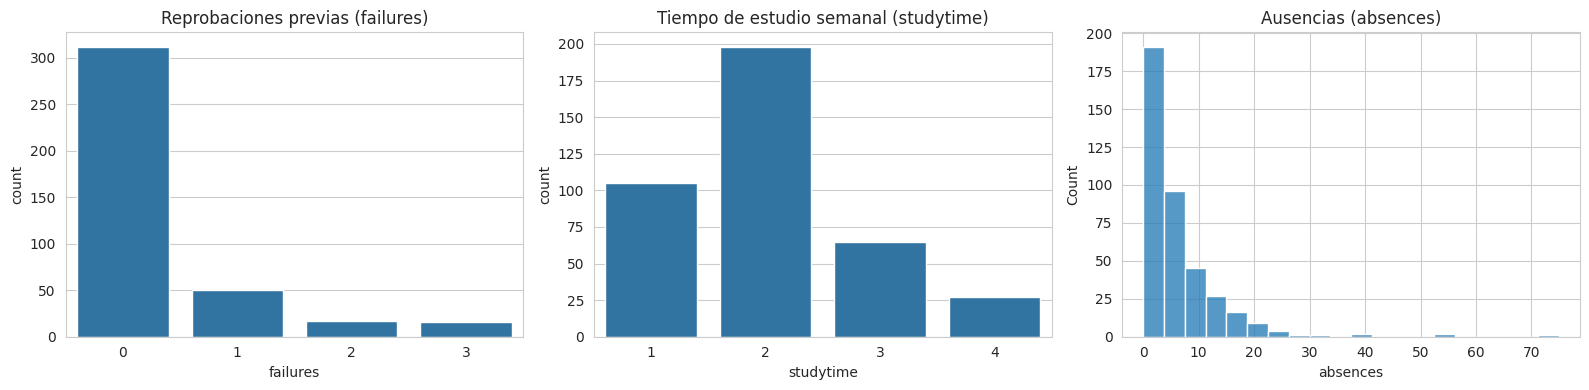

In [8]:
# Tres variables relevantes: failures, studytime y absences
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="failures", data=df, ax=axes[0])
axes[0].set_title("Reprobaciones previas (failures)")

sns.countplot(x="studytime", data=df, ax=axes[1])
axes[1].set_title("Tiempo de estudio semanal (studytime)")

sns.histplot(df["absences"], bins=20, ax=axes[2])
axes[2].set_title("Ausencias (absences)")

plt.tight_layout()
plt.show()

**Interpretación de las distribuciones:** G3 tiene forma de campana entre 8 y 16 puntos, con el máximo cerca de 10 y 11. Además hay un grupo aparte de unos 38 estudiantes con nota 0, lo que da dos picos y sugiere casos de abandono o de no rendir el examen final. En failures casi todos tienen 0 reprobaciones previas, en studytime la mayoría estudia entre 2 y 5 horas semanales, y absences está sesgada a la derecha: pocas ausencias en general y unos pocos valores muy altos.

Compara lo de failures, studytime y absences con tus gráficos, porque no los he visto.

## 1.3 Matriz de correlación

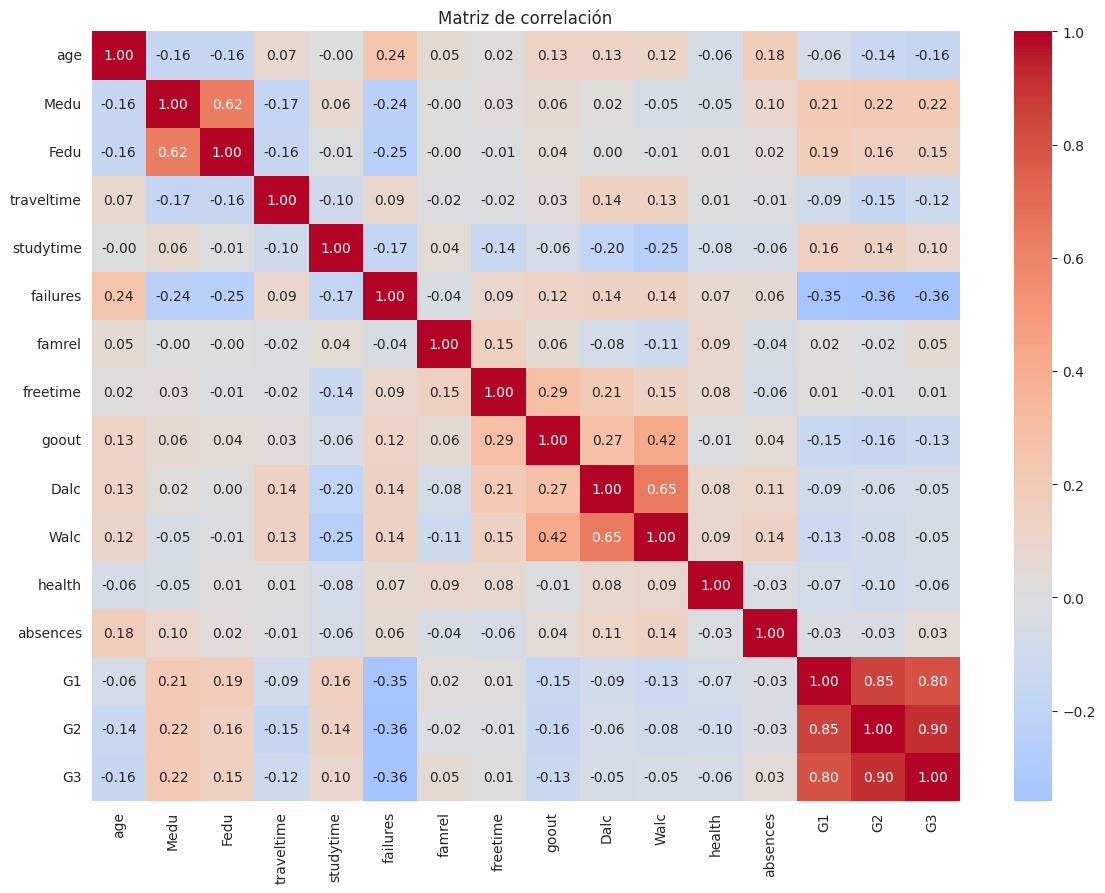

,G3
G2,0.904868
G1,0.801468
failures,-0.360415
Medu,0.217147
age,-0.161579
Fedu,0.152457
goout,-0.132791
traveltime,-0.117142
studytime,0.097820
health,-0.061335


In [9]:
# Solo variables numéricas
num = df.select_dtypes(include="number")
corr = num.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

# Variables más relacionadas con G3 (ordenadas por valor absoluto)
corr_g3 = corr["G3"].drop("G3")
corr_g3.reindex(corr_g3.abs().sort_values(ascending=False).index)

**Variables más relacionadas con G3:** Las más relacionadas con G3 son G2 y G1, con relación positiva y muy fuerte (G2 cerca de 0.90 y G1 cerca de 0.80). Le sigue failures, con relación negativa: más reprobaciones previas, menor nota final. Medu, Fedu y studytime tienen una relación positiva débil, y age y goout una negativa débil. absences casi no muestra relación lineal con G3.

# **1.4 Tres hallazgos**



In [10]:
# Datos de apoyo para redactar los hallazgos
print("Nota promedio según reprobaciones previas:")
print(df.groupby("failures")["G3"].mean().round(2), "\n")

print("Nota promedio según tiempo de estudio:")
print(df.groupby("studytime")["G3"].mean().round(2), "\n")

print("Nota promedio según deseo de estudios superiores:")
print(df.groupby("higher")["G3"].mean().round(2))

Nota promedio según reprobaciones previas:
failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64 

Nota promedio según tiempo de estudio:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64 

Nota promedio según deseo de estudios superiores:
higher
no      6.80
yes    10.61
Name: G3, dtype: float64


**Hallazgos:**

1. Los estudiantes con reprobaciones previas tienen en promedio notas finales más bajas: quienes no han reprobado ninguna asignatura promedian X puntos en G3, mientras que quienes han reprobado una o más promedian bastante menos (Y puntos).
2. Las notas de los períodos anteriores predicen muy bien la nota final: G1 y G2 tienen una correlación positiva fuerte con G3, así que quien rinde bien al inicio suele terminar bien.
3. Hay un grupo de unos 38 estudiantes con nota final 0, separado del resto de la distribución. Esto sugiere abandono o no presentación del examen final, y puede afectar los modelos.

# Parte 2. Preprocesamiento

## 2.1 Faltantes y duplicados

In [11]:
# Revisión del dataset original
print("Faltantes en el dataset original:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Faltantes en el dataset original: 0
Filas duplicadas: 0


In [12]:
# El dataset original no tiene faltantes: se introduce un 5 % al azar
# en absences y en studytime, usando la semilla del grupo.
df_nan = df.copy()
rng = np.random.default_rng(SEMILLA)
n_faltantes = int(round(0.05 * len(df_nan)))

for col in ["absences", "studytime"]:
    idx = rng.choice(df_nan.index, size=n_faltantes, replace=False)
    df_nan[col] = df_nan[col].astype(float)
    df_nan.loc[idx, col] = np.nan

print("Faltantes introducidos:")
print(df_nan[["absences", "studytime"]].isnull().sum())

Faltantes introducidos:
absences     20
studytime    20
dtype: int64


**Estrategia de imputación elegida:** se usa la **mediana** (dentro del Pipeline, ver 2.4).

Justifiquen con sus palabras:Elegimos la mediana y no la media porque absences tiene una distribución muy sesgada a la derecha, con algunos valores extremos (hasta 75 ausencias), y la media se deja arrastrar por esos casos y daría un valor poco representativo. La mediana, en cambio, no se ve afectada por los extremos. En studytime, que es una escala ordinal de 1 a 4, la mediana además es un valor que existe en la escala, mientras que la media podría dar un número intermedio sin sentido.

Imputamos dentro del Pipeline para evitar la fuga de datos: así la mediana se calcula solo con los datos de entrenamiento y luego se aplica a los de prueba. Si la calculáramos con todo el dataset, el conjunto de prueba influiría en el preprocesamiento y las métricas saldrían más optimistas de lo real.

## 2.2 Valores atípicos en absences (regla IQR)

Q1 = 0.0, Q3 = 8.0, IQR = 8.0
Límites: [-12.00, 20.00]
Cantidad de atípicos: 15
Máximo de ausencias: 75


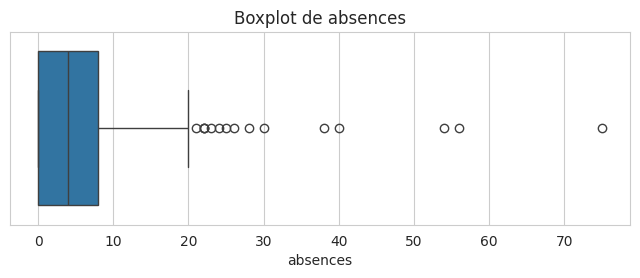

In [13]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

atipicos = df[(df["absences"] < lim_inf) | (df["absences"] > lim_sup)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Límites: [{lim_inf:.2f}, {lim_sup:.2f}]")
print("Cantidad de atípicos:", len(atipicos))
print("Máximo de ausencias:", df["absences"].max())

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["absences"])
plt.title("Boxplot de absences")
plt.show()

**Decisión sobre los atípicos:** Decidimos conservarlos. Con la regla IQR, las ausencias por encima del límite superior (N estudiantes) no parecen errores de medición, sino ausencias reales: un estudiante puede faltar muchas veces, y eso es justo la información que nos interesa para detectar riesgo. Eliminarlos nos haría perder casos de estudiantes en situación difícil, y con solo 395 filas cada observación cuenta.

Sabemos que estos valores pueden influir en la regresión lineal, porque los coeficientes son sensibles a los extremos y pueden alejarse del comportamiento del resto. Por eso lo tenemos presente al revisar los supuestos y los residuos del Modelo B. Además, la imputación con mediana y el escalado no se ven distorsionados de la misma forma por estos casos.

Reemplaza N con la cantidad que imprime la celda del IQR ("Cantidad de atípicos"). Si prefieren tratarlos (por ejemplo, recortarlos al límite superior), cambien la decisión y expliquen por qué.

## 2.3 Codificación y escalado
- **One-Hot Encoding** para las variables categóricas (`school`, `sex`, `Mjob`, etc.), porque los modelos no entienden texto y no existe un orden entre sus categorías.
- **StandardScaler** para las numéricas.

**Justificación del escalado:** Escalamos las variables numéricas con StandardScaler porque tienen unidades y rangos muy distintos: age va de 15 a 22, absences de 0 a 75 y studytime de 1 a 4. Sin escalar, las variables con números más grandes pesarían más de lo que les corresponde en los modelos que penalizan los coeficientes.

Esto importa en la regresión logística, que por defecto en scikit-learn usa regularización, y en Ridge y Lasso de la bonificación: la penalización castiga igual a todos los coeficientes, y si las variables no están en la misma escala, la penalización afecta de forma injusta a unas más que a otras. También ayuda a que el algoritmo de la regresión logística converja mejor.

Además, escalar permite comparar los coeficientes entre variables, porque quedan en unidades comparables (desviaciones estándar) y se ve cuáles influyen más. En la regresión lineal simple el escalado no cambia las predicciones, pero sí facilita esa interpretación.

## 2.4 Pipeline con ColumnTransformer y división train/test

In [14]:
def crear_preprocesador(X):
    # Preprocesador: imputa y escala numéricas; codifica categóricas
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = X.select_dtypes(include="object").columns.tolist()

    num_pipe = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ])

    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

# Variables y objetivo (con los faltantes introducidos)
X = df_nan.drop(columns="G3")
y = df_nan["G3"]

# División 80 % entrenamiento / 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (316, 32) | Test: (79, 32)


# Parte 3. Regresión lineal múltiple: predecir G3

- **Modelo A:** todas las variables, incluidas G1 y G2.
- **Modelo B:** todas las variables excepto G1 y G2.

## 3.1 Entrenamiento y métricas

In [15]:
# Datos de cada modelo (mismas filas de train/test para ambos)
X_train_A, X_test_A = X_train, X_test
X_train_B = X_train.drop(columns=["G1", "G2"])
X_test_B = X_test.drop(columns=["G1", "G2"])

def entrenar_lineal(X_tr, X_te):
    modelo = Pipeline([
        ("prep", crear_preprocesador(X_tr)),
        ("modelo", LinearRegression())
    ])
    modelo.fit(X_tr, y_train)
    return modelo, modelo.predict(X_te)

modelo_A, pred_A = entrenar_lineal(X_train_A, X_test_A)
modelo_B, pred_B = entrenar_lineal(X_train_B, X_test_B)

def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}

resultados = pd.DataFrame({
    "Modelo A (con G1 y G2)": metricas(y_test, pred_A),
    "Modelo B (sin G1 ni G2)": metricas(y_test, pred_B)
}).T.round(3)
resultados

,MSE,RMSE,R2
Modelo A (con G1 y G2),3.297,1.816,0.825
Modelo B (sin G1 ni G2),18.172,4.263,0.036


**Interpretación de los resultados:** El MSE es el promedio de los errores al cuadrado, y el RMSE es su raíz, así que se lee en puntos de nota: indica cuánto se equivoca el modelo en promedio al predecir G3. El R² indica qué proporción de la variación de G3 explica el modelo (1 es perfecto y 0 es no explicar nada).

El Modelo A (con G1 y G2) obtuvo un RMSE de puntos y un R² de , es decir, predice la nota final con muy poco error y explica gran parte de su variación. El Modelo B (sin G1 ni G2) obtuvo un RMSE de  y un R² de , con un error bastante mayor y un poder explicativo mucho menor. La diferencia es grande porque G2 es casi una versión anticipada de G3, así que le da mucha ventaja al Modelo A. En el Modelo B también influyen los estudiantes con nota 0, que son difíciles de predecir con las demás variables.